# Tutorial for `Geocroissant`: Multi-Temporal Time-Series Support 🥐

<img src="../assets/geocr.jpg" alt="GeoCroissant" width="150" style="float: right; margin-left: 50px;">
In this tutorial, we demonstrate how to build time-series support in GeoCroissant for the first 3 months of the year (January, February, March) 

In [1]:
# Install dependencies if not already present:
# !pip install mlcroissant rasterio pystac-client torch matplotlib

import os
import json
import time
import hashlib
import urllib.request
from datetime import datetime
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import matplotlib.pyplot as plt
import rasterio
from rasterio.enums import Resampling
from rasterio.windows import Window
import torch
from torch.utils.data import Dataset, DataLoader
from pystac_client import Client
import mlcroissant as mlc

## 1. Dynamic Time-Series Range Selector

In [2]:
BBOX = [-115.3, 35.8, -114.5, 36.4]

# Date range for the first 3 months
START_DATE = "2023-01-01"
END_DATE = "2023-03-31"

# Maximum cloud cover percentage threshold
MAX_CLOUD_COVER = 5.0

# Target MGRS Tile
MGRS_TILE = "11SPV"

print("Time-Series Range Configuration:")
print(f"  Bounding Box:     {BBOX}")
print(f"  Temporal Window:  {START_DATE} to {END_DATE} (First 3 Months)")
print(f"  Max Cloud Cover:  {MAX_CLOUD_COVER}%")
print(f"  Target Tile:      MGRS-{MGRS_TILE}")

Time-Series Range Configuration:
  Bounding Box:     [-115.3, 35.8, -114.5, 36.4]
  Temporal Window:  2023-01-01 to 2023-03-31 (First 3 Months)
  Max Cloud Cover:  5.0%
  Target Tile:      MGRS-11SPV


## 2. Dynamic STAC Query: 1 Image Per Month

We connect to the public **AWS Earth Search STAC API** and search for observations matching our parameters. The query groups observations by calendar month (`YYYY-MM`) and selects the cleanest, cloud-free observation for each of the first 3 months.

In [3]:
def query_monthly_timeseries(bbox, start_date, end_date, max_cloud=5.0, tile="11SPV"):
    """Dynamically query STAC API for Sentinel-2 L2A scenes, selecting 1 scene per month."""
    client = Client.open("https://earth-search.aws.element84.com/v1")

    search = client.search(
        collections=["sentinel-2-l2a"],
        bbox=bbox,
        datetime=f"{start_date}/{end_date}",
        query={
            "eo:cloud_cover": {"lt": max_cloud},
            "grid:code": {"eq": f"MGRS-{tile}"},
        },
        sortby=[{"field": "properties.datetime", "direction": "asc"}],
        limit=50,
    )

    # Group items by month (YYYY-MM)
    monthly_groups = {}
    for item in search.items():
        month_key = item.datetime.strftime("%Y-%m")
        if month_key not in monthly_groups:
            monthly_groups[month_key] = []
        monthly_groups[month_key].append(item)

    # For each month, select the observation with lowest cloud cover
    selected_scenes = []
    month_names = ["Month 1 (January)", "Month 2 (February)", "Month 3 (March)"]

    for idx, (m_key, items) in enumerate(sorted(monthly_groups.items())):
        if idx >= 3:
            break
        best_item = min(items, key=lambda x: x.properties.get("eo:cloud_cover", 100))
        selected_scenes.append({
            "id": best_item.id,
            "datetime": best_item.datetime.strftime("%Y-%m-%dT%H:%M:%SZ"),
            "date": best_item.datetime.strftime("%Y-%m-%d"),
            "month": month_names[idx] if idx < len(month_names) else f"Month {idx+1}",
            "cloud_cover": float(best_item.properties.get("eo:cloud_cover", 0.0)),
            "assets": best_item.assets,
            "base_url": f"https://sentinel-cogs.s3.us-west-2.amazonaws.com/sentinel-s2-l2a-cogs/11/S/PV/{best_item.datetime.year}/{best_item.datetime.month}/{best_item.id}/",
        })

    return selected_scenes


selected_scenes = query_monthly_timeseries(
    BBOX, START_DATE, END_DATE, MAX_CLOUD_COVER, MGRS_TILE
)

print(
    f"Successfully retrieved {len(selected_scenes)} monthly observations across first 3"
    " months:"
)
for s in selected_scenes:
    print(
        f"  [{s['month']}] ID: {s['id']} | Date: {s['date']} | Cloud:"
        f" {s['cloud_cover']:.2f}%"
    )

Successfully retrieved 3 monthly observations across first 3 months:
  [Month 1 (January)] ID: S2B_11SPV_20230125_0_L2A | Date: 2023-01-25 | Cloud: 0.05%
  [Month 2 (February)] ID: S2A_11SPV_20230209_0_L2A | Date: 2023-02-09 | Cloud: 0.16%
  [Month 3 (March)] ID: S2A_11SPV_20230331_0_L2A | Date: 2023-03-31 | Cloud: 0.03%


## 3. Dynamic SHA-256 Checksum Verification

GeoCroissant requires verified checksums (`sha256`) for every remote asset in the `distribution`.

In [4]:
# Helper function to compute or load SHA-256 dynamically
SHA_CACHE_FILE = "sha256_cache.json"


def load_sha_cache(cache_file=SHA_CACHE_FILE):
    if os.path.exists(cache_file):
        with open(cache_file, "r") as f:
            return json.load(f)
    return {}


def save_sha_cache(cache, cache_file=SHA_CACHE_FILE):
    with open(cache_file, "w") as f:
        json.dump(cache, f, indent=2)


def get_sha256(scene_id, band_name, url, cache):
    """Retrieve SHA-256 from cache or compute dynamically over HTTP streaming."""
    cache_key = f"{scene_id}_{band_name}"
    if cache_key in cache:
        return cache[cache_key]

    print(f"Computing SHA-256 dynamically for {cache_key}...")
    h = hashlib.sha256()
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req) as resp:
        while chunk := resp.read(2 * 1024 * 1024):
            h.update(chunk)
    digest = h.hexdigest()
    cache[cache_key] = digest
    save_sha_cache(cache)
    return digest


sha_cache = load_sha_cache()
print(f"Loaded {len(sha_cache)} precomputed SHA-256 checksums from {SHA_CACHE_FILE}.")

Loaded 39 precomputed SHA-256 checksums from sha256_cache.json.


## 4. Define GeoCroissant Metadata

We now construct the full GeoCroissant metadata covering:

In [5]:
# All 12 Sentinel-2 Level-2A spectral bands definition
BANDS = [
    ("B01", "coastal", "Coastal aerosol", 443, 27, 60),
    ("B02", "blue", "Blue", 490, 98, 10),
    ("B03", "green", "Green", 560, 45, 10),
    ("B04", "red", "Red", 665, 38, 10),
    ("B05", "rededge1", "Red Edge 1", 704, 19, 20),
    ("B06", "rededge2", "Red Edge 2", 740, 18, 20),
    ("B07", "rededge3", "Red Edge 3", 783, 28, 20),
    ("B08", "nir", "NIR 1", 842, 145, 10),
    ("B8A", "nir08", "NIR 2", 865, 33, 20),
    ("B09", "nir09", "Water vapour", 945, 26, 60),
    ("B11", "swir16", "SWIR 1", 1610, 143, 20),
    ("B12", "swir22", "SWIR 2", 2190, 242, 20),
]

file_objects = []
records = []
spectral_bands = []

# Base fields for the RecordSet
fields = [
    mlc.Field(
        id="scenes/scene_id",
        name="scene_id",
        data_types=[mlc.DataType.TEXT],
        description="Sentinel-2 unique product identifier",
    ),
    mlc.Field(
        id="scenes/datetime",
        name="datetime",
        data_types=[mlc.DataType.DATE],
        description="Acquisition ISO 8601 timestamp for temporal indexing",
    ),
    mlc.Field(
        id="scenes/month",
        name="month",
        data_types=[mlc.DataType.TEXT],
        description="Observation month (first 3 months)",
    ),
    mlc.Field(
        id="scenes/cloud_cover",
        name="cloud_cover",
        data_types=[mlc.DataType.FLOAT],
        description="Cloud cover percentage",
    ),
    mlc.Field(
        id="scenes/visual_url",
        name="visual_url",
        data_types=[mlc.DataType.URL],
        description="True Color Image (TCI) URL",
    ),
]

for b_name, asset_key, desc, cw, bw, res in BANDS:
    fields.append(
        mlc.Field(
            id=f"scenes/{b_name.lower()}_url",
            name=f"{b_name.lower()}_url",
            data_types=[mlc.DataType.URL],
            description=f"{desc} ({b_name}) Cloud-Optimized GeoTIFF URL",
        )
    )
    spectral_bands.append(
        mlc.SpectralBand(
            name=b_name,
            center_wavelength=mlc.QuantitativeValue(value=float(cw), unitText="nm"),
            bandwidth=mlc.QuantitativeValue(value=float(bw), unitText="nm"),
        )
    )

# Generate FileObjects with verified SHA-256 and populate record data
for s in selected_scenes:
    sid = s["id"]
    base = s["base_url"]
    tci_url = f"{base}TCI.tif"
    tci_sha = get_sha256(sid, "TCI", tci_url, sha_cache)

    file_objects.append(
        mlc.FileObject(
            id=f"{sid}_TCI",
            name=f"{sid}_TCI.tif",
            description=f"Visual True Color Image (10m) for {s['month']} ({s['date']})",
            content_url=tci_url,
            encoding_formats=[
                "image/tiff; application=geotiff; profile=cloud-optimized"
            ],
            sha256=tci_sha,
        )
    )

    rec = {
        "scenes/scene_id": sid,
        "scenes/datetime": s["datetime"],
        "scenes/month": s["month"],
        "scenes/cloud_cover": s["cloud_cover"],
        "scenes/visual_url": tci_url,
    }

    for b_name, asset_key, desc, cw, bw, res in BANDS:
        url = f"{base}{b_name}.tif"
        b_sha = get_sha256(sid, b_name, url, sha_cache)
        file_objects.append(
            mlc.FileObject(
                id=f"{sid}_{b_name}",
                name=f"{sid}_{b_name}.tif",
                description=f"{desc} ({b_name}) at {res}m resolution for {s['month']}",
                content_url=url,
                encoding_formats=[
                    "image/tiff; application=geotiff; profile=cloud-optimized"
                ],
                sha256=b_sha,
            )
        )
        rec[f"scenes/{b_name.lower()}_url"] = url

    records.append(rec)

# Define RecordSet and Metadata
scenes_rs = mlc.RecordSet(
    id="scenes",
    name="scenes",
    description=(
        "First 3 months Sentinel-2 Level-2A monthly observations indexed"
        " chronologically for time-series modeling"
    ),
    data=records,
    fields=fields,
)

metadata = mlc.Metadata(
    name="sentinel2-timeseries-first-3-months",
    description=(
        "Multi-temporal Sentinel-2 Level-2A time-series observations across the first 3"
        " months of 2023 (January, February, March) over Lake Mead and Las Vegas with"
        " full 12-band spectral coverage."
    ),
    cite_as=(
        "@article{CopernicusSentinel2, title={Copernicus Sentinel-2 MSI Level-2A},"
        " author={European Space Agency}, year={2023},"
        " url={https://doi.org/10.5270/S2_-742ikth}}"
    ),
    date_published="2023-03-31",
    keywords=[
        "remote sensing",
        "sentinel-2",
        "time-series",
        "first-3-months",
        "multispectral",
        "earth-observation",
    ],
    license="https://creativecommons.org/licenses/by/4.0/",
    url="https://earth-search.aws.element84.com/v1/collections/sentinel-2-l2a",
    version="1.0.0",
    distribution=file_objects,
    record_sets=[scenes_rs],
    coordinate_reference_system="EPSG:32611",
    spatial_resolution=mlc.QuantitativeValue(value=10.0, unitText="m"),
    band_configuration=mlc.BandConfiguration(
        total_bands=len(BANDS),
        band_names_list=[b[0] for b in BANDS],
    ),
    spectral_band_metadata=spectral_bands,
    spatial_coverage={
        "@type": "Place",
        "geo": {
            "@type": "GeoShape",
            "box": "35.133016 -115.902135 36.139732 -114.668797",
        },
    },
)

# Convert to JSON-LD and append GeoCroissant Time-Series extensions
meta_json = metadata.to_json()
meta_json["conformsTo"] = [
    "http://mlcommons.org/croissant/1.1",
    "http://mlcommons.org/croissant/geo/1.0",
]
meta_json["temporalCoverage"] = f"{START_DATE}/{END_DATE}"
meta_json["geocr:temporalResolution"] = {
    "@type": "QuantitativeValue",
    "value": 1,
    "unitText": "month",
}

# Attach geocr:timeSeriesIndex to the RecordSet
for rs in meta_json["recordSet"]:
    if rs.get("@id") == "scenes":
        rs["geocr:timeSeriesIndex"] = {"@id": "scenes/datetime"}

jsonld_path = "sentinel2_timeseries.json"
with open(jsonld_path, "w") as f:
    json.dump(meta_json, f, indent=2)

print(f"Successfully generated GeoCroissant metadata: {jsonld_path}")
print(f"Total FileObjects:     {len(file_objects)} (all 12 spectral bands + TCI)")
print(f"Temporal Coverage:     {meta_json['temporalCoverage']}")
print(
    "Temporal Resolution:  "
    f" {meta_json['geocr:temporalResolution']['value']} {meta_json['geocr:temporalResolution']['unitText']}"
)

Successfully generated GeoCroissant metadata: sentinel2_timeseries.json
Total FileObjects:     39 (all 12 spectral bands + TCI)
Temporal Coverage:     2023-01-01/2023-03-31
Temporal Resolution:   1 month


## 5. Validate Metadata with `mlcroissant`

We run the official `mlcroissant validate` command to verify that our metadata passes all strict schema and specification checks.

In [6]:
!mlcroissant validate --jsonld=sentinel2_timeseries.json

I1107 15:10:39.604032 135949826496320 validate.py:53] Done.


## 6. Load Dataset & Inspect Monthly Temporal Index

We load the dataset using `mlcroissant.Dataset` and verify the chronologically indexed observations across the first 3 months.

In [7]:
dataset = mlc.Dataset("sentinel2_timeseries.json")
print("Loaded Dataset Name:", dataset.metadata.name)
print("Total FileObjects in distribution:", len(dataset.metadata.distribution))

print("\nInspecting chronologically indexed monthly records:")
for record in dataset.records("scenes"):
    print(
        f"  [{record['scenes/month']:18s}] Date: {record['scenes/datetime'][:10]} |"
        f" Cloud: {record['scenes/cloud_cover']:.2f}% | ID: {record['scenes/scene_id']}"
    )
    print(f"    Blue:  {record['scenes/b02_url'].split('/')[-1]}")
    print(f"    Red:   {record['scenes/b04_url'].split('/')[-1]}")
    print(f"    NIR:   {record['scenes/b08_url'].split('/')[-1]}")
    print(f"    SWIR1: {record['scenes/b11_url'].split('/')[-1]}")

Loaded Dataset Name: sentinel2-timeseries-first-3-months
Total FileObjects in distribution: 39

Inspecting chronologically indexed monthly records:
  [Month 1 (January) ] Date: 2023-01-25 | Cloud: 0.05% | ID: S2B_11SPV_20230125_0_L2A
    Blue:  B02.tif
    Red:   B04.tif
    NIR:   B08.tif
    SWIR1: B11.tif
  [Month 2 (February)] Date: 2023-02-09 | Cloud: 0.16% | ID: S2A_11SPV_20230209_0_L2A
    Blue:  B02.tif
    Red:   B04.tif
    NIR:   B08.tif
    SWIR1: B11.tif
  [Month 3 (March)   ] Date: 2023-03-31 | Cloud: 0.03% | ID: S2A_11SPV_20230331_0_L2A
    Blue:  B02.tif
    Red:   B04.tif
    NIR:   B08.tif
    SWIR1: B11.tif


## 7. PyTorch Multi-Temporal Dataset & DataLoader

In [9]:
def resolve_path(filename):
    """Helper to resolve file paths whether running from repo root or notebook directory."""
    candidates = [
        filename,
        os.path.join("Notebooks/GeoCroissant Time-Series Support", filename),
        os.path.join(
            os.path.dirname(__file__) if "__file__" in locals() else ".", filename
        ),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    return filename


class Sentinel2DirectTimeSeriesDataset(Dataset):
    """PyTorch Dataset that streams Sentinel-2 time series directly from GeoCroissant metadata.

    Zero local file dependencies: accesses Cloud-Optimized GeoTIFFs (COGs) on AWS S3 directly.
    """

    def __init__(self, jsonld_path="sentinel2_timeseries.json", out_shape=(512, 512)):
        resolved_jsonld = resolve_path(jsonld_path)
        self.dataset = mlc.Dataset(resolved_jsonld)
        self.records = list(self.dataset.records("scenes"))
        self.out_shape = out_shape
        # Selected multispectral bands: Blue, Green, Red, NIR, SWIR1
        self.band_keys = ["b02_url", "b03_url", "b04_url", "b08_url", "b11_url"]

    def __len__(self):
        return 1  # 1 temporal sequence of 3 months

    def __getitem__(self, idx):
        series_channels = []
        tci_list = []
        window_tci_list = []
        dates = []
        months = []

        # Native 10m window over Lake Mead & Hoover Dam
        win = Window(col_off=8500, row_off=1000, width=800, height=800)

        with rasterio.Env(AWS_NO_SIGN_REQUEST="YES"):
            for rec in self.records:
                dates.append(rec["scenes/datetime"][:10])
                months.append(rec["scenes/month"])

                # 1. Stream True Color Image (TCI) overview and native 10m detail window
                tci_url = rec["scenes/visual_url"]
                with rasterio.open(tci_url) as src:
                    tci_overview = src.read(
                        out_shape=(3, self.out_shape[0], self.out_shape[1]),
                        resampling=Resampling.bilinear,
                    )
                    tci_list.append(np.transpose(tci_overview, (1, 2, 0)))

                    win_img = src.read(window=win)
                    window_tci_list.append(np.transpose(win_img, (1, 2, 0)))

                # 2. Stream multispectral channels: [B02, B03, B04, B08, B11]
                channels = []
                for bk in self.band_keys:
                    with rasterio.open(rec[f"scenes/{bk}"]) as src:
                        arr = src.read(
                            1, out_shape=self.out_shape, resampling=Resampling.bilinear
                        )
                        channels.append(arr.astype(np.float32) / 10000.0)
                series_channels.append(np.stack(channels, axis=0))  # (C, H, W)

        # Stack into temporal tensors: (T, C, H, W) and (T, H, W, 3)
        tensor = torch.from_numpy(np.stack(series_channels, axis=0)).float()
        tcis = np.stack(tci_list, axis=0)
        window_tcis = np.stack(window_tci_list, axis=0)

        return {
            "series": tensor,
            "tci": tcis,
            "window_tci": window_tcis,
            "dates": dates,
            "months": months,
        }


print("Streaming data directly from GeoCroissant metadata...")
ts_dataset = Sentinel2DirectTimeSeriesDataset(
    "sentinel2_timeseries.json", out_shape=(512, 512)
)
ts_loader = DataLoader(ts_dataset, batch_size=1, shuffle=False)

batch = next(iter(ts_loader))
series_tensor = batch["series"][0]  # Remove batch dim -> (T, C, H, W)

print(f"PyTorch Time-Series Batch Shape (T, C, H, W): {series_tensor.shape}")
print(
    f"Temporal steps (T):  {series_tensor.shape[0]} ({', '.join(batch['months'][0])})"
)
print(f"Spectral bands (C):  {series_tensor.shape[1]} (Blue, Green, Red, NIR, SWIR)")
print(
    f"Spatial size (H, W): {series_tensor.shape[2]} x {series_tensor.shape[3]} pixels"
)

Streaming data directly from GeoCroissant metadata...
PyTorch Time-Series Batch Shape (T, C, H, W): torch.Size([3, 5, 512, 512])
  Temporal steps (T):  3 (Month 1 (January))
  Spectral bands (C):  5 (Blue, Green, Red, NIR, SWIR)
  Spatial size (H, W): 512 x 512 pixels


## 8. Full-Resolution Multi-Temporal Visualizations

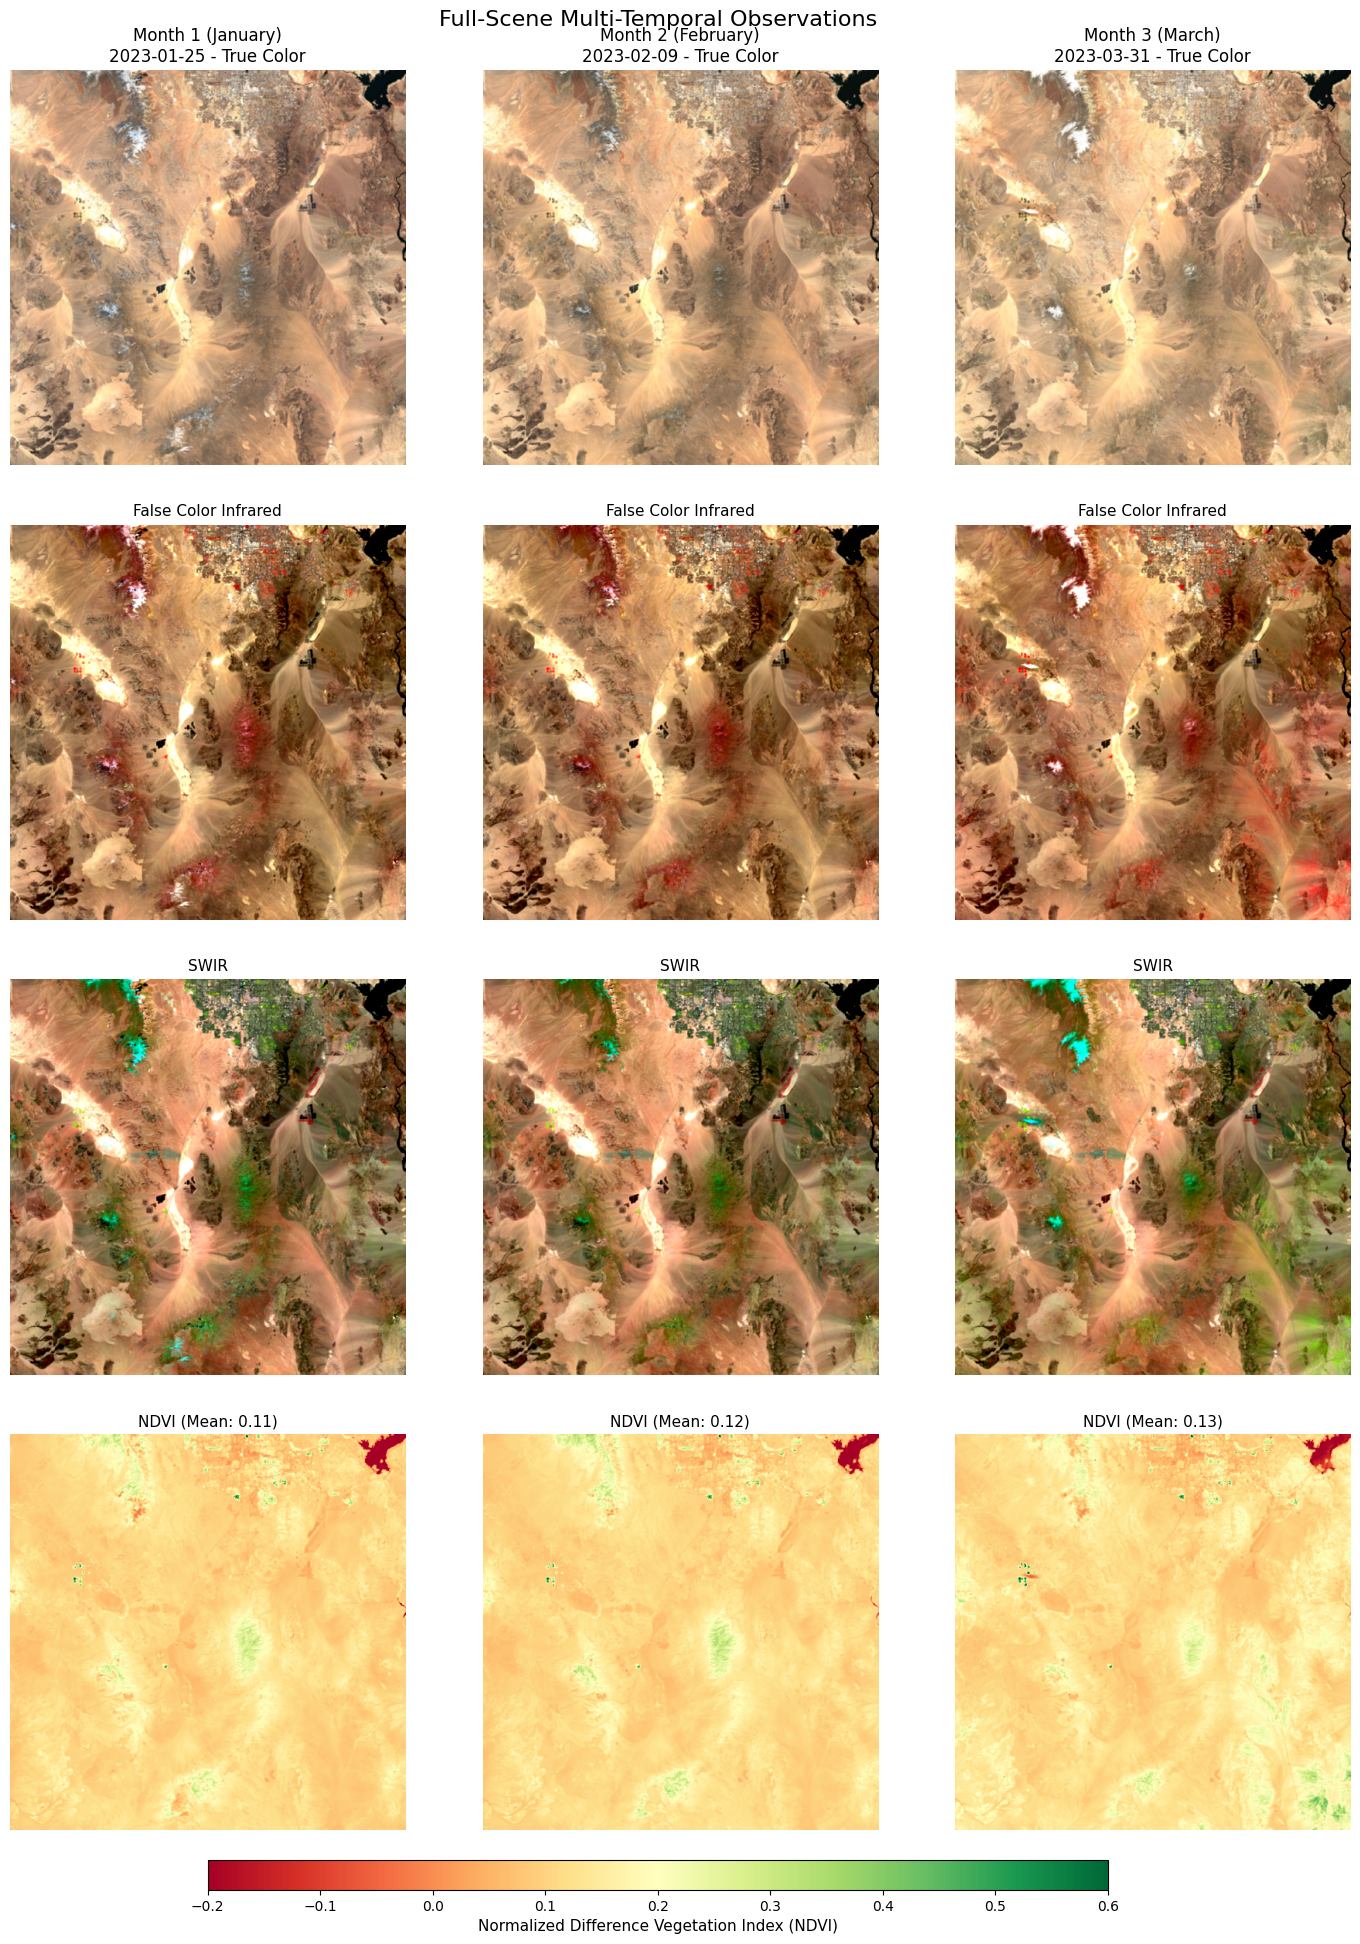

In [10]:
# Extract bands from the tensor
blues = series_tensor[:, 0, :, :].numpy()
greens = series_tensor[:, 1, :, :].numpy()
reds = series_tensor[:, 2, :, :].numpy()
nirs = series_tensor[:, 3, :, :].numpy()
swirs = series_tensor[:, 4, :, :].numpy()
tcis = batch["tci"][0].numpy()
months = [m[0] for m in batch["months"]]
dates = [d[0] for d in batch["dates"]]

# Compute NDVI: (NIR - Red) / (NIR + Red + 1e-6)
ndvis = (nirs - reds) / (nirs + reds + 1e-6)

# Create 4-row multi-temporal comparison across the 3 months
fig, axes = plt.subplots(4, 3, figsize=(18, 20), facecolor="white")

for i in range(3):
    # Row 1: True Color (RGB)
    axes[0, i].imshow(tcis[i])
    axes[0, i].set_title(f"{months[i]}\n{dates[i]} - True Color", fontsize=12)
    axes[0, i].axis("off")

    # Row 2: False Color Infrared (CIR: NIR, Red, Green)
    cir = np.dstack([nirs[i], reds[i], greens[i]])
    p2, p98 = np.percentile(cir, (2, 98))
    cir_stretched = np.clip((cir - p2) / (p98 - p2 + 1e-6), 0.0, 1.0) ** 0.85
    axes[1, i].imshow(cir_stretched)
    axes[1, i].set_title("False Color Infrared", fontsize=11)
    axes[1, i].axis("off")

    # Row 3: SWIR Composite (SWIR1, NIR, Red)
    swir_comp = np.dstack([swirs[i], nirs[i], reds[i]])
    p2, p98 = np.percentile(swir_comp, (2, 98))
    swir_stretched = np.clip((swir_comp - p2) / (p98 - p2 + 1e-6), 0.0, 1.0) ** 0.85
    axes[2, i].imshow(swir_stretched)
    axes[2, i].set_title("SWIR", fontsize=11)
    axes[2, i].axis("off")

    # Row 4: Normalized Difference Vegetation Index (NDVI)
    im = axes[3, i].imshow(ndvis[i], cmap="RdYlGn", vmin=-0.2, vmax=0.6)
    axes[3, i].set_title(f"NDVI (Mean: {ndvis[i].mean():.2f})", fontsize=11)
    axes[3, i].axis("off")

# Shared colorbar for NDVI
cbar_ax = fig.add_axes([0.25, 0.04, 0.5, 0.015])
cbar = fig.colorbar(im, cax=cbar_ax, orientation="horizontal")
cbar.set_label("Normalized Difference Vegetation Index (NDVI)", fontsize=11)

plt.subplots_adjust(top=0.95, bottom=0.07, hspace=0.15, wspace=0.05)
plt.suptitle("Full-Scene Multi-Temporal Observations", fontsize=16, y=0.98)
plt.show()